# Scagnostics (scatterplot diagnostics)

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Scores every pairwise scatterplot of a dataset on measures of shape such as outlying, skewed, clumpy, sparse, striated, stringy and monotonic, computed from the minimum spanning tree of the points. A heatmap of measure × pair then points the analyst to the few scatterplots worth looking at, instead of scanning dozens or hundreds of panels in a scatterplot matrix.

## When to use

- Screen many numeric variables (stock characteristics, risk factors, KPIs) for unusual pairwise patterns
- Pick which scatterplots to show from a pair plot that is too big to read
- Flag pairs with outliers, clusters or discrete stripes before modelling

## Avoid when

- Fewer than about 5 variables; just draw the pair plot
- You already know which relationship matters
- Very small samples, where the spanning-tree measures are noisy

## Alternatives

- Pair plot (scatterplot matrix)
- Correlation heatmap (linear association only)
- Parallel coordinates

## Design tips

- What it adds: a correlation heatmap only sees straight-line association; scagnostics also catch clusters, outliers, stripes and strings that correlation misses
- Each axis is min-max scaled to [0, 1] first, as in the original method, so measures compare across pairs (rank scaling would hide outliers)
- Outliers are removed before the other measures are computed, as in the original method
- This implementation computes 7 of the 9 original measures; convex and skinny need an alpha-shape hull and are omitted

## Example

Eight simulated characteristics for 400 stocks in four sectors: size, beta, volatility, dividend yield, P/E, ROE, 12-month momentum and debt-to-equity.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from itertools import combinations
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr

### Data

In [2]:
rng = np.random.default_rng(12)
n = 400
sector = rng.choice(["Tech", "Utilities", "Financials", "Energy"], n, p=[0.35, 0.2, 0.25, 0.2])
beta = np.select([sector == "Tech", sector == "Utilities", sector == "Financials"], [1.3, 0.5, 1.0], 1.1)
beta = beta + rng.normal(0, 0.18, n)
stocks = pd.DataFrame({
    "Size (log cap)": rng.normal(10, 1.2, n),
    "Beta": beta,
    "Volatility": 0.08 + 0.17 * beta + rng.normal(0, 0.015, n),
    "Dividend yield": np.select([sector == "Tech", sector == "Utilities"],
                                [rng.choice([0, 0, 0.5], n), rng.normal(4.5, 0.4, n)], rng.normal(2.2, 0.4, n)),
    "P/E": np.select([sector == "Tech", sector == "Utilities"],
                     [rng.normal(32, 3, n), rng.normal(16, 2, n)], rng.normal(12, 2, n)),
    "ROE": np.where(rng.random(n) < 0.03, rng.normal(-60, 15, n), rng.normal(14, 5, n)),
    "Momentum 12m": rng.normal(8, 20, n),
    "Debt/Equity": rng.lognormal(0, 0.7, n),
})
stocks.describe().round(2)

,Size (log cap),Beta,Volatility,Dividend yield,P/E,ROE,Momentum 12m,Debt/Equity
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,10.04,1.05,0.26,1.84,20.09,11.37,9.04,1.32
std,1.23,0.32,0.06,1.52,9.49,14.93,19.53,1.08
min,6.64,0.09,0.08,0.00,6.35,-91.50,-62.45,0.14
25%,9.19,0.86,0.23,0.50,12.27,10.70,-4.30,0.69
50%,10.02,1.10,0.27,1.95,15.24,13.84,9.11,1.04
75%,10.81,1.28,0.30,2.61,30.20,16.81,20.32,1.67
max,14.44,1.82,0.39,5.32,39.66,26.30,64.67,11.60


### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_33446/1702169983.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


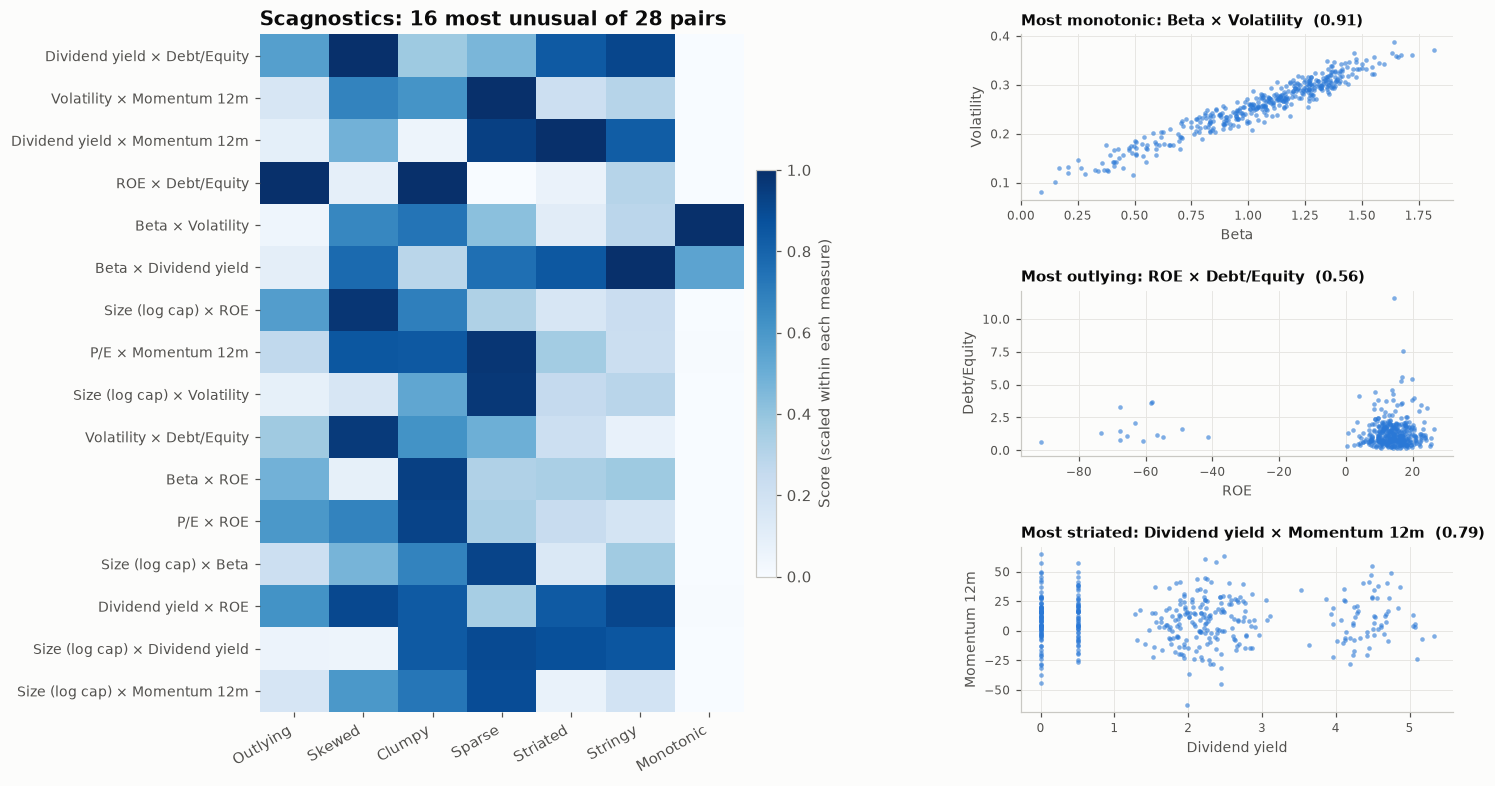

In [3]:
def scagnostics(x, y):
    P = np.c_[(x - x.min()) / np.ptp(x), (y - y.min()) / np.ptp(y)]  # min-max scale to [0, 1]
    def mst(points):
        T = minimum_spanning_tree(squareform(pdist(points))).tocoo()
        return T.row, T.col, T.data
    r, c, w = mst(P)
    q25, q50, q75, q90 = np.percentile(w, [25, 50, 75, 90])
    omega = q75 + 1.5 * (q75 - q25)
    outlying = w[w > omega].sum() / w.sum()
    # Remove points whose every MST edge is long (outliers), then recompute the tree.
    long_edge = w > omega
    deg_all = np.bincount(np.r_[r, c], minlength=len(P))
    deg_long = np.bincount(np.r_[r[long_edge], c[long_edge]], minlength=len(P))
    keep = ~((deg_all > 0) & (deg_all == deg_long))
    P = P[keep]
    r, c, w = mst(P)
    q10, q50, q90 = np.percentile(w, [10, 50, 90])
    skewed = (q90 - q50) / (q90 - q10)
    sparse = q90
    deg = np.bincount(np.r_[r, c], minlength=len(P))
    stringy = (deg == 2).sum() / max(len(P) - (deg == 1).sum(), 1)
    # Striated: share of degree-2 vertices whose two edges are nearly collinear (cos < -0.75).
    nbrs = [[] for _ in range(len(P))]
    for a, b in zip(r, c):
        nbrs[a].append(b)
        nbrs[b].append(a)
    cosines = []
    for v in np.where(deg == 2)[0]:
        u1, u2 = P[nbrs[v][0]] - P[v], P[nbrs[v][1]] - P[v]
        cosines.append(u1 @ u2 / (np.linalg.norm(u1) * np.linalg.norm(u2) + 1e-12))
    striated = np.mean(np.array(cosines) < -0.75) if cosines else 0.0
    # Clumpy: cut each edge; compare it with the longest edge in the smaller piece.
    clumpy = 0.0
    adj = np.zeros((len(P), len(P)))
    adj[r, c] = w
    for j in np.argsort(w)[::-1][:60]:                           # the long edges are the candidates
        A = adj.copy()
        A[r[j], c[j]] = 0
        _, comp = connected_components(A, directed=False)
        small = comp == np.argmin(np.bincount(comp))
        inner = w[small[r] & small[c]]
        if len(inner):
            clumpy = max(clumpy, 1 - inner.max() / w[j])
    monotonic = spearmanr(x, y).statistic ** 2
    return dict(Outlying=outlying, Skewed=skewed, Clumpy=clumpy, Sparse=sparse,
                Striated=striated, Stringy=stringy, Monotonic=monotonic)

pairs = list(combinations(stocks.columns, 2))
scores = pd.DataFrame([scagnostics(stocks[a].to_numpy(), stocks[b].to_numpy()) for a, b in pairs],
                      index=[f"{a} × {b}" for a, b in pairs])
scaled = (scores - scores.min()) / (scores.max() - scores.min())  # 0-1 within each measure
show = scaled.loc[scaled.max(axis=1).sort_values(ascending=False).index[:16]]

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(3, 2, width_ratios=[1.35, 1], hspace=0.55, wspace=0.35)
ax = fig.add_subplot(gs[:, 0])
im = ax.imshow(show.to_numpy(), cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(show.shape[1]), show.columns, rotation=30, ha="right")
ax.set_yticks(range(len(show)), show.index, fontsize=9)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Scagnostics: 16 most unusual of 28 pairs")
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02, label="Score (scaled within each measure)")

for i, measure in enumerate(["Monotonic", "Outlying", "Striated"]):
    best = scores[measure].idxmax()
    a, b = best.split(" × ")
    axs = fig.add_subplot(gs[i, 1])
    axs.scatter(stocks[a], stocks[b], s=9, color=PALETTE[0], alpha=0.6, linewidth=0)
    axs.set_xlabel(a, fontsize=9)
    axs.set_ylabel(b, fontsize=9)
    axs.set_title(f"Most {measure.lower()}: {a} × {b}  ({scores.loc[best, measure]:.2f})", fontsize=10)
    axs.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

## How to read it

In the heatmap, dark cells are the pairs that score high on a measure. Beta vs. volatility is the most monotonic pair; the ROE pairs are the most outlying (a few loss-making firms far from the rest) and also clumpy, because those firms form their own clump; dividend-yield pairs score high on striated and stringy, because many tech stocks pay exactly 0% or 0.5%. The three panels on the right show the top pair for monotonic, outlying and striated, so you can check each flag by eye.

## Reference

This method comes from the research literature:

- Wilkinson, L., Anand, A. & Grossman, R. (2005). Graph-theoretic scagnostics. Proceedings of the IEEE Symposium on Information Visualization (InfoVis 2005), 157–164. 20-Year Test of Time Award, IEEE VIS 2025. <https://tableau.com/research/publications/graph-theoretic-scagnostics>

---
Standalone script: [`scagnostics.py`](scagnostics.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)